# Compressor Health Clustering

## 1. Feature Engineering and Window Design

This notebook continues from the saved findings in notebook 01. It validates the inputs, measures compressor-state dwell times, compares candidate non-overlapping time windows, and builds window-level sensor features. It preserves chronology and breaks windows at timestamp gaps greater than 30 seconds.

The 5-minute window below is a **starting candidate**, not a final modeling decision. Review the state-dwell and coverage outputs before accepting it. The supplied data have a median 10-second interval and include gaps up to about 48 hours, so this notebook never interpolates or bridges long gaps.

Run from the project root or `notebooks/`. This notebook is intentionally unexecuted.

## 2. Import Libraries and Set Up Paths

Use the same dark charcoal visual style as notebook 01. The project root is discovered from the current directory or its parents.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA_RELATIVE_PATH = Path("data") / "raw" / "metropt+3+dataset" / "MetroPT3(AirCompressor).csv"
PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / DATA_RELATIVE_PATH).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project data folder from the current directory. "
        "Open this notebook within the project checkout."
    )
DATA_PATH = PROJECT_ROOT / DATA_RELATIVE_PATH

PALETTE = {
    "blue": "#72B7F2", "teal": "#4FD1C5", "amber": "#F6C177",
    "red": "#F28B82", "gray": "#AAB6C2", "figure_bg": "#151B23",
    "axes_bg": "#202833", "text": "#E6EDF3", "muted_text": "#B8C4D0",
    "grid": "#3B4653",
}
sns.set_theme(style="darkgrid", context="notebook", font="DejaVu Sans", font_scale=1.0)
plt.rcParams.update({
    "figure.figsize": (11, 5), "figure.dpi": 120,
    "figure.facecolor": PALETTE["figure_bg"],
    "savefig.facecolor": PALETTE["figure_bg"],
    "axes.facecolor": PALETTE["axes_bg"],
    "axes.edgecolor": PALETTE["grid"],
    "axes.labelcolor": PALETTE["text"],
    "axes.titlecolor": PALETTE["text"],
    "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": PALETTE["muted_text"],
    "ytick.color": PALETTE["muted_text"], "text.color": PALETTE["text"],
    "grid.color": PALETTE["grid"], "grid.alpha": 0.55,
})
print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset: {DATA_PATH}")

Project root: c:\Projects_Tracking\Compressor_Health_Clustering
Dataset: c:\Projects_Tracking\Compressor_Health_Clustering\data\raw\metropt+3+dataset\MetroPT3(AirCompressor).csv


## 3. Load the Source Data and Confirm Required Signals

Load the CSV once, parse timestamps, and explicitly exclude the sequential source index from all sensor features.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])

INDEX_COLUMN = "Unnamed: 0" if "Unnamed: 0" in df.columns else None
ANALOG_COLUMNS = [
    "TP2", "TP3", "H1", "DV_pressure", "Reservoirs",
    "Oil_temperature", "Motor_current",
]
DIGITAL_COLUMNS = [
    "COMP", "DV_eletric", "Towers", "MPG", "LPS",
    "Pressure_switch", "Oil_level", "Caudal_impulses",
]
CORE_STATE_COLUMNS = ["COMP", "DV_eletric"]
REQUIRED_COLUMNS = ["timestamp", *ANALOG_COLUMNS, *DIGITAL_COLUMNS]
missing_columns = sorted(set(REQUIRED_COLUMNS) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required dataset columns are missing: {missing_columns}")

print(f"Rows: {len(df):,} | Sensor signals: {len(ANALOG_COLUMNS) + len(DIGITAL_COLUMNS)}")
print(f"Index-like column excluded from features: {INDEX_COLUMN}")
display(df[["timestamp", *ANALOG_COLUMNS, *DIGITAL_COLUMNS]].head())

Rows: 1,516,948 | Sensor signals: 15
Index-like column excluded from features: Unnamed: 0


,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


## 4. Recheck Data Integrity and Define Gap Boundaries

Do not silently sort, drop, or interpolate records. This notebook stops if timestamps are invalid or unordered so that any repair can be reviewed first. A gap above 30 seconds starts a new segment; the threshold is three times the observed 10-second median interval.

In [3]:
interval_s = df["timestamp"].diff().dt.total_seconds()
nominal_interval_s = float(interval_s[interval_s > 0].median())
GAP_THRESHOLD = pd.Timedelta(seconds=max(3 * nominal_interval_s, 30))

quality = pd.Series({
    "rows": len(df),
    "missing_timestamps": int(df["timestamp"].isna().sum()),
    "duplicate_timestamps": int(df["timestamp"].duplicated().sum()),
    "out_of_order_steps": int((interval_s < 0).sum()),
    "missing_sensor_values": int(df[REQUIRED_COLUMNS[1:]].isna().sum().sum()),
    "median_interval_seconds": nominal_interval_s,
    "gap_threshold_seconds": GAP_THRESHOLD.total_seconds(),
    "gaps_over_threshold": int((interval_s > GAP_THRESHOLD.total_seconds()).sum()),
})
display(quality.to_frame("value"))

if df["timestamp"].isna().any() or not df["timestamp"].is_monotonic_increasing:
    raise ValueError("Resolve invalid or unordered timestamps before feature engineering.")
if df["timestamp"].duplicated().any():
    raise ValueError("Resolve duplicate timestamps before feature engineering.")
if df[REQUIRED_COLUMNS[1:]].isna().any().any():
    raise ValueError("Review missing sensor readings before feature engineering; none are filled here.")

gap_before = interval_s > GAP_THRESHOLD.total_seconds()
segment_id = gap_before.cumsum().astype("int32")
print(f"Continuous time segments separated by long gaps: {segment_id.nunique():,}")

,value
rows,1516948.0
missing_timestamps,0.0
duplicate_timestamps,0.0
out_of_order_steps,0.0
missing_sensor_values,0.0
median_interval_seconds,10.0
gap_threshold_seconds,30.0
gaps_over_threshold,331.0


Continuous time segments separated by long gaps: 332


## 5. Inspect Digital Encodings and Operating-State Dwell Times

The source documentation describes `COMP` and `DV_eletric` as compressor valve signals. Here we use their observed binary combinations as state codes only; the code does not assign health labels. Dwell durations are approximate because readings are sampled intermittently and timestamps are not perfectly regular.

,observed values
COMP,"[0.0, 1.0]"
DV_eletric,"[0.0, 1.0]"
Towers,"[0.0, 1.0]"
MPG,"[0.0, 1.0]"
LPS,"[0.0, 1.0]"
Pressure_switch,"[0.0, 1.0]"
Oil_level,"[0.0, 1.0]"
Caudal_impulses,"[0.0, 1.0]"


,run_count,median_seconds,p25_seconds,p75_seconds,max_seconds
state_code,,,,,
0,9057,10.0,10.0,10.0,46.0
1,14362,129.0,73.0,139.0,108417.0
2,15629,843.0,58.0,1229.0,2735.0
3,1453,46.0,46.0,58.0,155.0


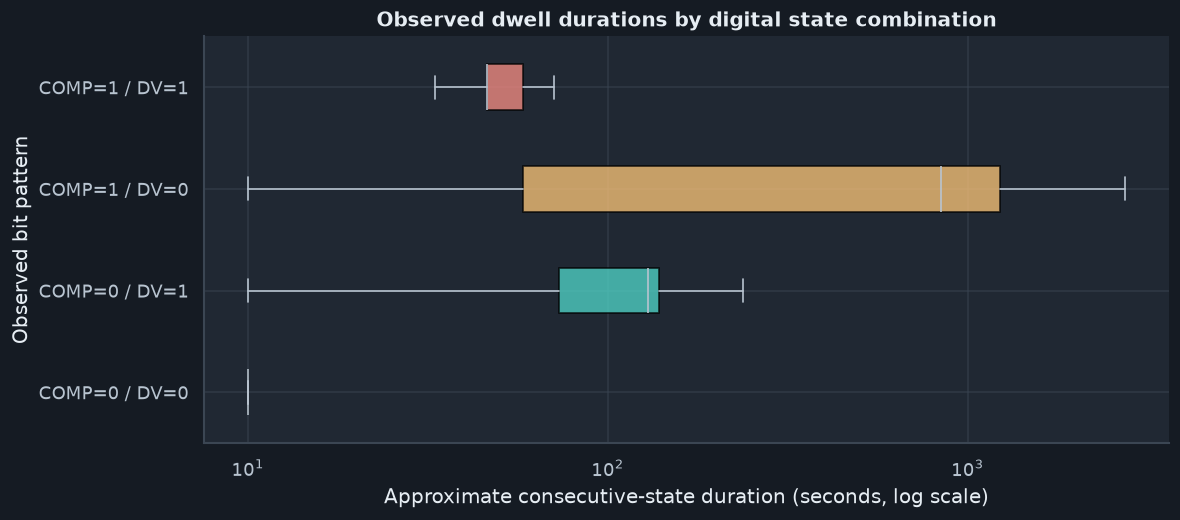

In [4]:
digital_values = {column: sorted(df[column].dropna().unique().tolist()) for column in DIGITAL_COLUMNS}
display(pd.Series(digital_values, name="observed values").to_frame())
nonbinary = {column: values for column, values in digital_values.items() if not set(values).issubset({0, 1})}
if nonbinary:
    raise ValueError(f"Signals expected to be binary contain other values: {nonbinary}")

state_code = (df["COMP"].astype("int8") * 2 + df["DV_eletric"].astype("int8"))
state_change = state_code.ne(state_code.shift())
run_start = state_change | gap_before
run_id = run_start.cumsum().astype("int32")
runs = pd.DataFrame({"timestamp": df["timestamp"], "state_code": state_code, "run_id": run_id})
dwell = (
    runs.groupby("run_id", sort=False)
        .agg(state_code=("state_code", "first"),
             first_timestamp=("timestamp", "first"),
             last_timestamp=("timestamp", "last"),
             sample_count=("timestamp", "size"))
        .reset_index(drop=True)
)
dwell["duration_seconds"] = (
    (dwell["last_timestamp"] - dwell["first_timestamp"]).dt.total_seconds()
    + nominal_interval_s
)
dwell_summary = (
    dwell.groupby("state_code")["duration_seconds"]
         .agg(run_count="size", median_seconds="median", p25_seconds=lambda s: s.quantile(0.25),
              p75_seconds=lambda s: s.quantile(0.75), max_seconds="max")
         .round(1)
)
display(dwell_summary)

fig, ax = plt.subplots(figsize=(10, 4.5))
box_data = [dwell.loc[dwell["state_code"] == code, "duration_seconds"].to_numpy() for code in range(4)]
state_labels = ["COMP=0 / DV=0", "COMP=0 / DV=1", "COMP=1 / DV=0", "COMP=1 / DV=1"]
box = ax.boxplot(box_data, orientation="horizontal", patch_artist=True, showfliers=False)
ax.set_yticks(np.arange(1, len(state_labels) + 1))
ax.set_yticklabels(state_labels)
for patch, color in zip(box["boxes"], [PALETTE["blue"], PALETTE["teal"], PALETTE["amber"], PALETTE["red"]]):
    patch.set_facecolor(color)
    patch.set_alpha(0.78)
for element in ("whiskers", "caps", "medians"):
    for artist in box[element]:
        artist.set_color(PALETTE["muted_text"])
ax.set_xscale("log")
ax.set(title="Observed dwell durations by digital state combination",
       xlabel="Approximate consecutive-state duration (seconds, log scale)", ylabel="Observed bit pattern")
fig.tight_layout()
plt.show()

**Interpretation prompt:** Use the median and interquartile dwell times to judge whether candidate windows are much shorter than typical state periods or are likely to average across many transitions. Do not interpret a state code as healthy or faulty.

## 6. Compare Candidate Non-Overlapping Window Durations

Compare 1-, 5-, and 15-minute windows within continuous segments. The coverage fraction is a simple sample-count check against the observed median cadence; partial windows remain visible and are not silently removed.

,window,window_count,median_samples,windows_at_least_80pct_coverage
0,1min,252539,6.0,99.8
1,5min,50584,30.0,99.7
2,15min,16980,91.0,98.5


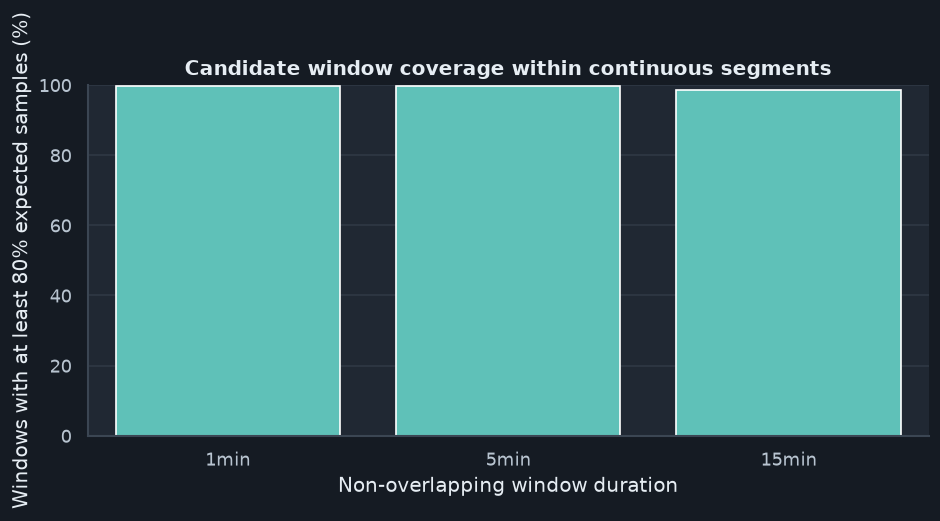

In [5]:
candidate_rules = ["1min", "5min", "15min"]
window_base = pd.DataFrame({"timestamp": df["timestamp"], "segment_id": segment_id})
window_base["segment_start"] = window_base.groupby("segment_id")["timestamp"].transform("first")
candidate_rows = []
for rule in candidate_rules:
    duration = pd.Timedelta(rule)
    window_number = ((window_base["timestamp"] - window_base["segment_start"]) // duration).astype("int32")
    counts = window_base.groupby(["segment_id", window_number], sort=True).size()
    expected_samples = duration.total_seconds() / nominal_interval_s
    coverage = (counts / expected_samples).clip(upper=1.0)
    candidate_rows.append({
        "window": rule,
        "window_count": len(counts),
        "median_samples": float(counts.median()),
        "windows_at_least_80pct_coverage": float((coverage >= 0.80).mean() * 100),
    })
candidate_summary = pd.DataFrame(candidate_rows)
display(candidate_summary.round(1))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=candidate_summary, x="window", y="windows_at_least_80pct_coverage",
            color=PALETTE["teal"], ax=ax)
ax.set(title="Candidate window coverage within continuous segments",
       xlabel="Non-overlapping window duration",
       ylabel="Windows with at least 80% expected samples (%)", ylim=(0, 100))
fig.tight_layout()
plt.show()

## 7. Set a Provisional Feature Window

Start with non-overlapping 5-minute windows (about 30 samples at the observed 10-second median cadence). This is a practical candidate for summarizing short sensor behavior, but it must be reviewed against the dwell-time table and candidate-coverage chart above. If the dwell times show that five minutes routinely merges distinct states, change `WINDOW` and rerun this notebook before modeling.

In [6]:
WINDOW = "5min"  # Provisional; revise after reviewing the dwell and coverage outputs.
MIN_COVERAGE = 0.80
print(f"Provisional window: {WINDOW} | Advisory coverage threshold: {MIN_COVERAGE:.0%}")

Provisional window: 5min | Advisory coverage threshold: 80%


## 8. Build Window-Level Features Without Crossing Gaps

For each time window, calculate means, standard deviations, minima, and maxima for analog sensors; fractions of rows with value 1 for binary signals; and transition counts for the two core compressor-state signals. Keep coverage and timestamps in separate metadata so they cannot enter the clustering matrix accidentally.

In [7]:
def build_window_features(data, window, gap_threshold, nominal_interval_seconds):
    """Create non-overlapping features within contiguous timestamp segments."""
    delta = pd.Timedelta(window)
    work = data[["timestamp", *ANALOG_COLUMNS, *DIGITAL_COLUMNS]].copy()
    elapsed = work["timestamp"].diff().dt.total_seconds()
    work["segment_id"] = (elapsed > gap_threshold.total_seconds()).cumsum().astype("int32")
    segment_start = work.groupby("segment_id")["timestamp"].transform("first")
    work["window_id"] = ((work["timestamp"] - segment_start) // delta).astype("int32")
    keys = ["segment_id", "window_id"]
    grouped = work.groupby(keys, sort=True, observed=True)

    analog = grouped[ANALOG_COLUMNS].agg(["mean", "std", "min", "max"])
    analog.columns = [f"{sensor}__{stat}" for sensor, stat in analog.columns]
    digital = grouped[DIGITAL_COLUMNS].mean().add_suffix("__fraction_value_1")
    metadata = grouped.agg(
        window_start=("timestamp", "min"),
        window_end=("timestamp", "max"),
        n_samples=("timestamp", "size"),
    )

    transitions_per_row = (
        work.groupby("segment_id", sort=False)[CORE_STATE_COLUMNS]
            .diff().abs().sum(axis=1, min_count=1).fillna(0)
    )
    transitions = transitions_per_row.groupby(
        [work["segment_id"], work["window_id"]], sort=True
    ).sum().to_frame("core_state_transitions")

    features = pd.concat([analog, digital, transitions], axis=1).sort_index()
    expected_samples = delta.total_seconds() / nominal_interval_seconds
    metadata["coverage_fraction"] = (metadata["n_samples"] / expected_samples).clip(upper=1.0)
    metadata["meets_coverage_threshold"] = metadata["coverage_fraction"] >= MIN_COVERAGE
    metadata = metadata.sort_index()
    return features, metadata

features, window_metadata = build_window_features(
    df, window=WINDOW, gap_threshold=GAP_THRESHOLD,
    nominal_interval_seconds=nominal_interval_s,
)

print(f"Feature matrix: {features.shape[0]:,} windows x {features.shape[1]:,} numeric features")
print(f"Windows meeting coverage threshold: {window_metadata['meets_coverage_threshold'].mean():.1%}")
print("Feature names:")
print(features.columns.tolist())
display(window_metadata.head())

Feature matrix: 50,584 windows x 37 numeric features
Windows meeting coverage threshold: 99.7%
Feature names:
['TP2__mean', 'TP2__std', 'TP2__min', 'TP2__max', 'TP3__mean', 'TP3__std', 'TP3__min', 'TP3__max', 'H1__mean', 'H1__std', 'H1__min', 'H1__max', 'DV_pressure__mean', 'DV_pressure__std', 'DV_pressure__min', 'DV_pressure__max', 'Reservoirs__mean', 'Reservoirs__std', 'Reservoirs__min', 'Reservoirs__max', 'Oil_temperature__mean', 'Oil_temperature__std', 'Oil_temperature__min', 'Oil_temperature__max', 'Motor_current__mean', 'Motor_current__std', 'Motor_current__min', 'Motor_current__max', 'COMP__fraction_value_1', 'DV_eletric__fraction_value_1', 'Towers__fraction_value_1', 'MPG__fraction_value_1', 'LPS__fraction_value_1', 'Pressure_switch__fraction_value_1', 'Oil_level__fraction_value_1', 'Caudal_impulses__fraction_value_1', 'core_state_transitions']


window_start          window_end  n_samples  \
segment_id window_id                                                      
0          0         2020-02-01 00:00:00 2020-02-01 00:04:57         31   
           1         2020-02-01 00:05:07 2020-02-01 00:09:55         30   
           2         2020-02-01 00:10:04 2020-02-01 00:14:52         30   
           3         2020-02-01 00:15:02 2020-02-01 00:19:59         31   
           4         2020-02-01 00:20:09 2020-02-01 00:24:57         30   

                      coverage_fraction  meets_coverage_threshold  
segment_id window_id                                               
0          0                        1.0                      True  
           1                        1.0                      True  
           2                        1.0                      True  
           3                        1.0                      True  
           4                        1.0                      True

## 9. Review Feature Quality and Coverage

Check missing feature values before clustering. Standard deviation is undefined for one-sample windows; low-coverage windows are flagged in metadata and remain available for review rather than being silently dropped.

In [8]:
feature_quality = pd.DataFrame({
    "missing_count": features.isna().sum(),
    "missing_percent": features.isna().mean() * 100,
}).sort_values("missing_count", ascending=False)
display(feature_quality.head(12).round(2))
display(window_metadata["coverage_fraction"].describe().to_frame("coverage_fraction"))

if features.index.nlevels != 2:
    raise AssertionError("Expected segment and window identifiers in the feature index.")
if any(column in features.columns for column in ["timestamp", INDEX_COLUMN]):
    raise AssertionError("Timestamp or source index leaked into the feature matrix.")
print("Timestamp and source index are metadata only; raw input data remain unchanged.")

,missing_count,missing_percent
TP2__std,5,0.01
DV_pressure__std,5,0.01
Reservoirs__std,5,0.01
H1__std,5,0.01
TP3__std,5,0.01
Motor_current__std,5,0.01
Oil_temperature__std,5,0.01
TP2__min,0,0.00
TP2__mean,0,0.00
TP3__mean,0,0.00


,coverage_fraction
count,50584.000000
mean,0.991136
std,0.047576
min,0.033333
25%,1.000000
50%,1.000000
75%,1.000000
max,1.000000


Timestamp and source index are metadata only; raw input data remain unchanged.


## 10. Inspect Engineered Feature Distributions and Redundancy

View selected window features and correlations among analog sensor means. This is a diagnostic for feature scale and redundancy; scaling and final feature selection belong in the clustering workflow.

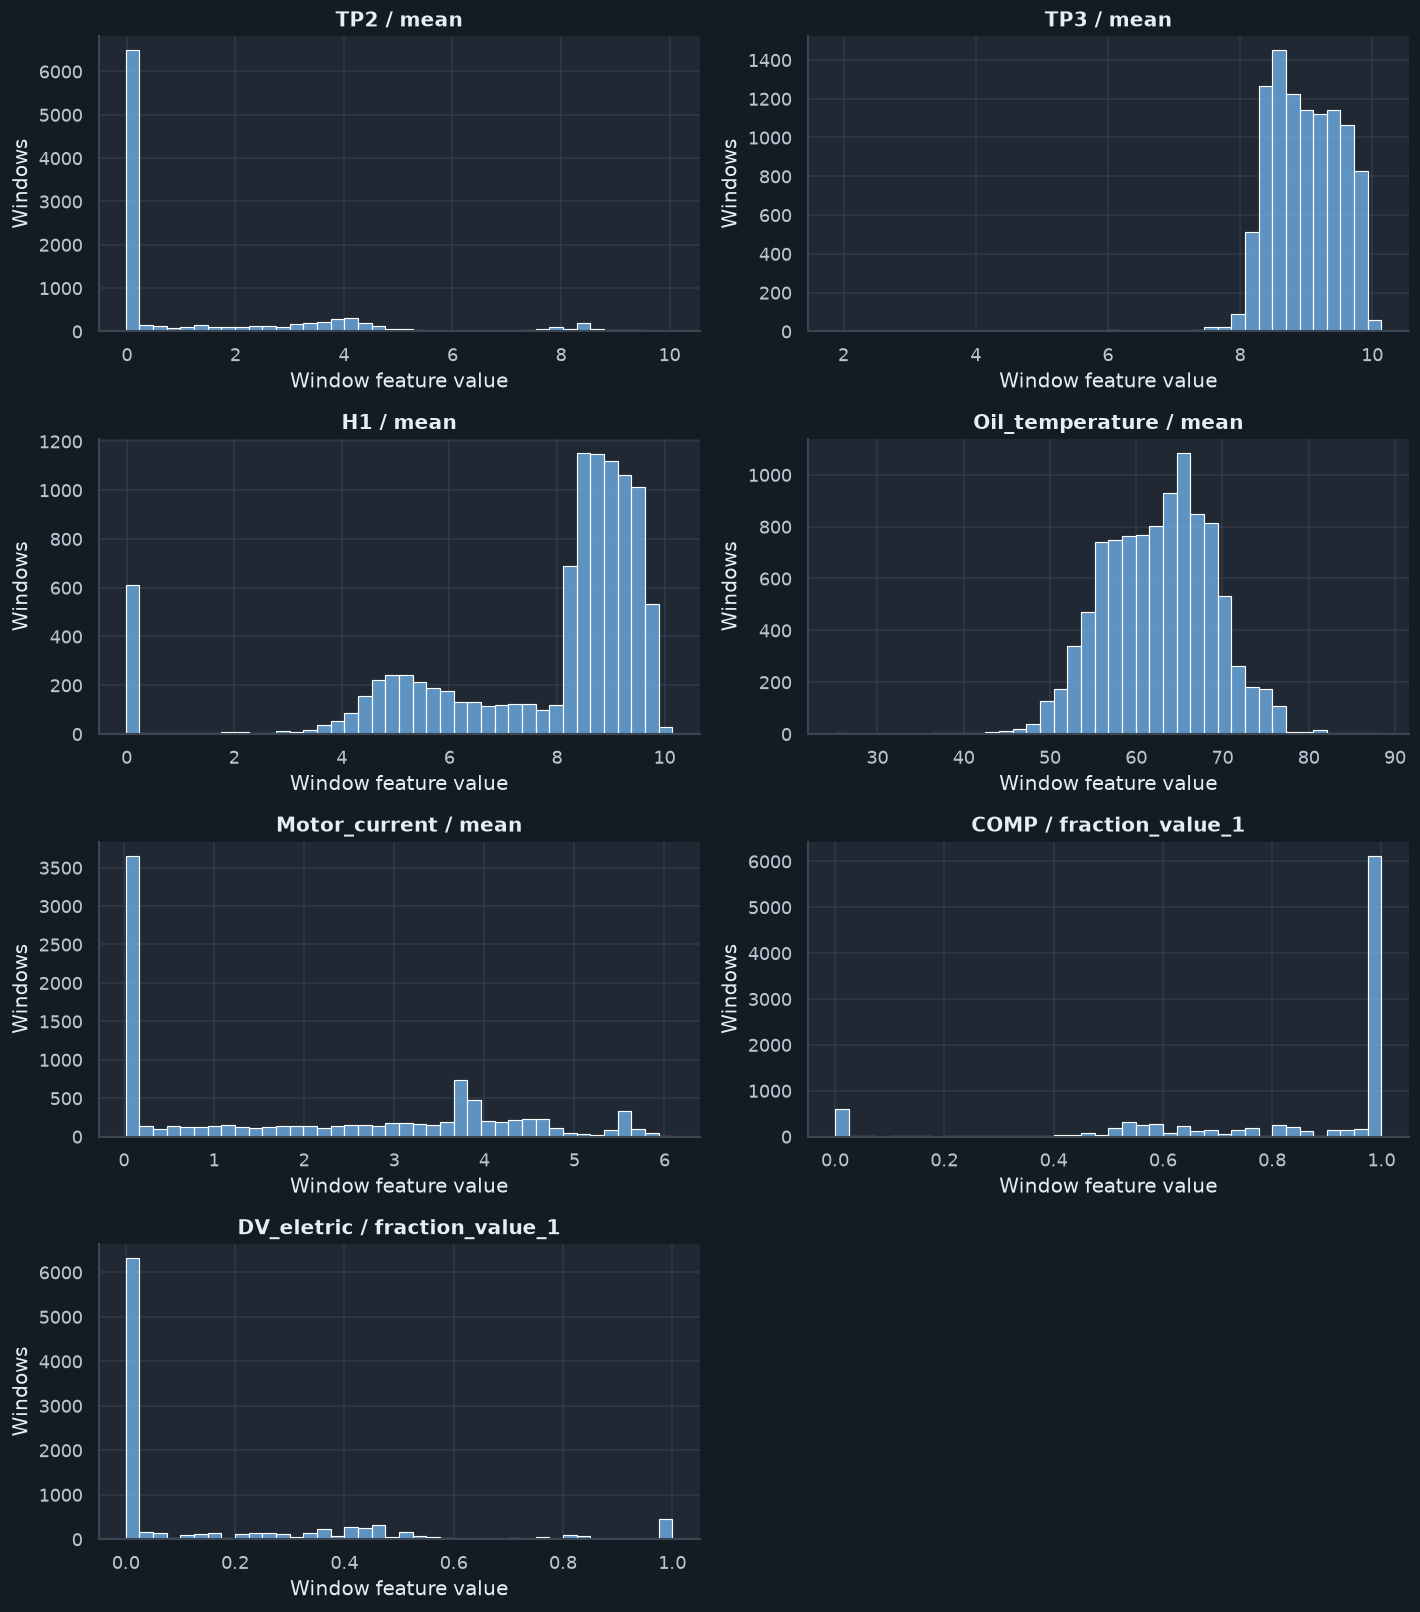

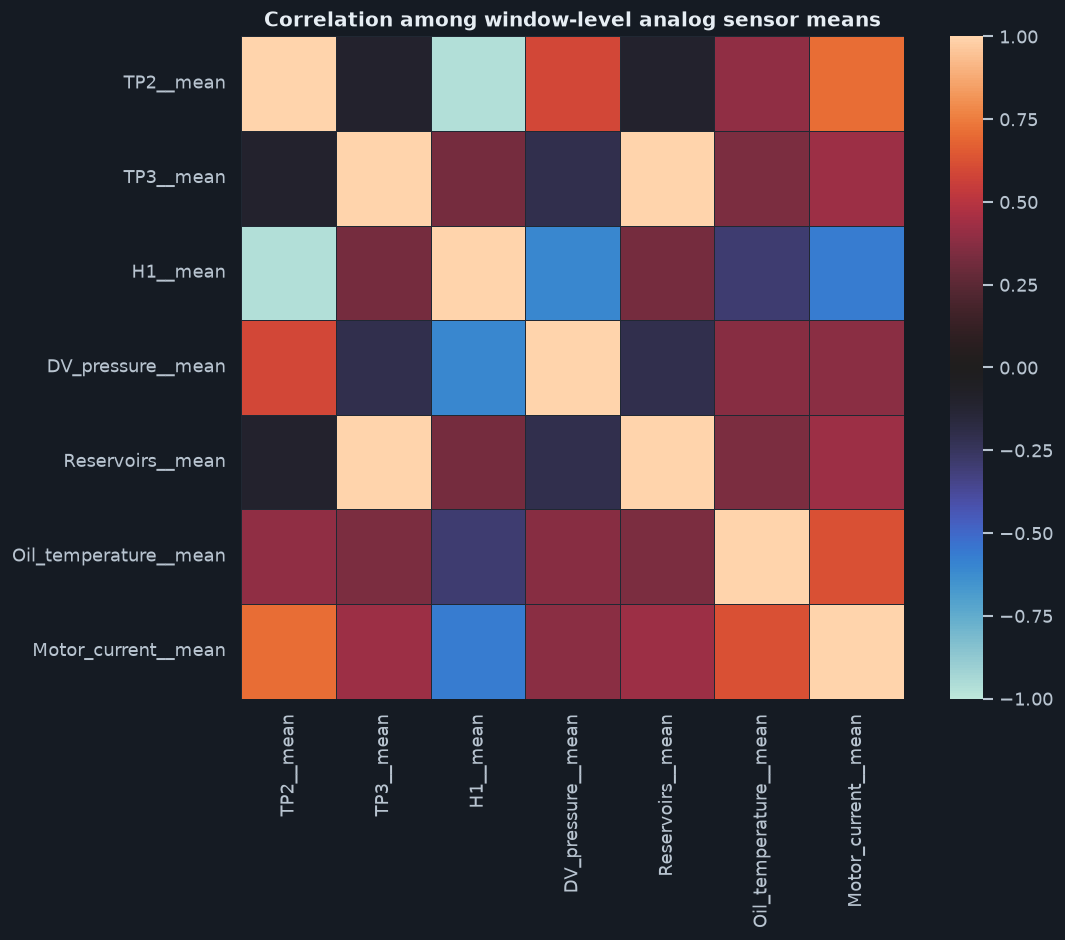

In [9]:
selected_features = [
    "TP2__mean", "TP3__mean", "H1__mean", "Oil_temperature__mean",
    "Motor_current__mean", "COMP__fraction_value_1", "DV_eletric__fraction_value_1",
]
selected_features = [column for column in selected_features if column in features.columns]
plot_features = features[selected_features].sample(
    n=min(10_000, len(features)), random_state=42
)

ncols = 2
nrows = int(np.ceil(len(selected_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.4 * nrows))
axes = np.asarray(axes).reshape(-1)
for ax, column in zip(axes, selected_features):
    sns.histplot(plot_features[column].dropna(), bins=40, color=PALETTE["blue"], ax=ax)
    ax.set_title(column.replace("__", " / "))
    ax.set_xlabel("Window feature value")
    ax.set_ylabel("Windows")
for ax in axes[len(selected_features):]:
    ax.remove()
fig.tight_layout()
plt.show()

mean_features = [column for column in features.columns if column.endswith("__mean")]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(features[mean_features].corr(), cmap="icefire", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, linecolor=PALETTE["axes_bg"], ax=ax)
ax.collections[0].colorbar.ax.tick_params(colors=PALETTE["muted_text"])
ax.collections[0].colorbar.outline.set_edgecolor(PALETTE["grid"])
ax.set_title("Correlation among window-level analog sensor means")
fig.tight_layout()
plt.show()

## 11. Save the Feature Table and Window Metadata

Write the compact engineered table to `data/processed/`. The feature CSV contains numeric sensor summaries only; window identifiers, timestamps, sample counts, and coverage are saved separately as metadata. The raw CSV is never modified.

In [10]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
window_label = WINDOW.replace(" ", "")
feature_path = PROCESSED_DIR / f"metropt_window_features_{window_label}.csv"
metadata_path = PROCESSED_DIR / f"metropt_window_metadata_{window_label}.csv"

features.reset_index().to_csv(feature_path, index=False)
window_metadata.reset_index().to_csv(metadata_path, index=False)
print(f"Saved features: {feature_path}")
print(f"Saved metadata: {metadata_path}")

Saved features: c:\Projects_Tracking\Compressor_Health_Clustering\data\processed\metropt_window_features_5min.csv
Saved metadata: c:\Projects_Tracking\Compressor_Health_Clustering\data\processed\metropt_window_metadata_5min.csv


## 12. Findings and Limitations

### Findings from the saved outputs

- All eight digital signals contain only 0/1 values. The timestamp checks found **331 gaps over 30 seconds**, which split the source into **332 continuous segments**. No invalid, duplicated, or unordered timestamps and no missing source sensor values were reported.
- The observed `COMP`/`DV_eletric` bit-pattern dwell times differ substantially. Median dwell was **10 s** for code 0, **129 s** for code 1, **843 s** (about 14 min) for code 2, and **46 s** for code 3. These are descriptive patterns only; the codes are not fault labels.
- Among 1-, 5-, and 15-minute non-overlapping windows, at least 80% sample coverage was observed for **99.8%**, **99.7%**, and **98.5%** of windows, respectively. Five-minute windows contain a median of **30 samples**, close to the expected count at the observed 10-second cadence. This is a reasonable working compromise: it gives more samples per feature estimate than 1-minute windows while retaining more temporal detail than 15-minute windows.
- The 5-minute feature table contains **50,584 windows and 37 numeric features**: four summaries for each of seven analog signals, value-1 fractions for eight binary signals, and a `COMP`/`DV_eletric` transition count. **99.7%** of windows meet the 80% coverage threshold; mean coverage is **99.1%**.
- Five windows have undefined analog standard deviations because each contains only one observation; this is **0.01%** per standard-deviation feature. The coverage flag identifies these sparse windows. Keep the source outputs for audit, but exclude below-threshold windows from the initial clustering matrix.
- Feature distributions preserve near-zero pressure readings, distinct motor-current modes, and mixed state fractions. The window-level correlation chart still shows strong redundancy between `TP3` and `Reservoirs`; account for that when selecting or weighting features in the clustering notebook.

### Limitations

- Dwell durations are approximate at a roughly 10-second cadence, and the longest runs can be much longer than typical cycles. The box plot uses a logarithmic time axis and hides individual fliers; the accompanying table retains maxima.
- The 30-second threshold is a practical segmentation rule, not proof that every shorter interval is continuous or every longer pause is missing data. No interpolation is performed.
- The 80% coverage rule is advisory and based on the median observed cadence. It flags incomplete windows but does not correct them.
- Five-minute summaries can average together short state changes (the median dwell for two bit patterns is under one minute) while the binary fractions and transition count retain some of that information. Compare the final cluster interpretation against finer temporal behavior.
- These engineered features describe recorded operation. They do not encode health, fault severity, or failure probability.
